# Hotel Booking Cancellation Prediction
- This notebook explores the dataset `Hotel booking demand` and creates a 'Booking cancelation prediction model', based on the features from the dataset.

## 1. Setup:
- Install missing libraries (if any)
- Imports
- Data loading

In [1]:
!pip install catboost


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("../data/hotel_bookings.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [41]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


## 2. Data Cleaning:
- Drop `No-Show` rows from `reservation_status`, focus only on `Check-Out` vs `Canceled`
- Handle NA's:
  * Drop the 4 NA rows from `children`
  * Drop the `company` column, since 94% of it is missing
  * Impute `country` and `agent` NA's with `Unknown`
- Drop `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `reservation_status_date`, `reservation_status` `required_car_parking_spaces`, `total_of_special_requests`, and `adr` as these features may introduce target leakage and may not be available at booking time.
- The target variable is `is_canceled.`

In [6]:
df["reservation_status"].value_counts(dropna=False)

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

In [7]:
df = df[df["reservation_status"] != "No-Show"].copy()

df = df.dropna(subset=["children"]).copy()

print("Shape after filtering:", df.shape)

Shape after filtering: (118179, 32)


In [8]:
columns_to_drop = [
    "company",
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "adr"
]

df = df.drop(columns=columns_to_drop)

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


In [9]:
df_imputed = df.copy()

df_imputed["country"] = (
    df_imputed["country"]
    .fillna("Unknown")
    .astype(str)
)

df_imputed["agent"] = (
    pd.to_numeric(df_imputed["agent"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("Unknown")
)

print("Remaining missing values:")
print(df_imputed.isna().sum()[df_imputed.isna().sum() > 0])

print("\nFinal dataset shape:", df_imputed.shape)

Remaining missing values:
Series([], dtype: int64)

Final dataset shape: (118179, 23)


## 3. Prediction Scope
- The prediction is supposed to happen at booking time.
- Accordingly, any info that will only be known later, should be excluded to ensure no data leakage, from features unavailable at prediction time.
- This is crucial to ensure the model is not reliant on info that won't be available in real world scenarios
- Target variable `is_canceled` will be excluded from input features

## 4. EDA
Check the following:
- Target distribution
- Features distribution (Categorical + numerical)
- Linear correlation with target, for numerical features
- Feature importance with target, for categical features
- Correlation between numerical features and each other

### Prepare EDA features

In [10]:
TARGET = "is_canceled"

eda_df = df_imputed.copy()

X = eda_df.drop(columns=[TARGET])
y = eda_df[TARGET]

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

print("Dataset shape:", eda_df.shape)
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Dataset shape: (118179, 23)
Numerical features: 12
Categorical features: 10


### 4.1 Target Distribution

The target distribution is examined to understand the proportion of canceled and non-canceled reservations and determine whether class imbalance may affect model evaluation.

### Target distribution

,count,percentage
is_canceled,,
0,75166,63.603517
1,43013,36.396483


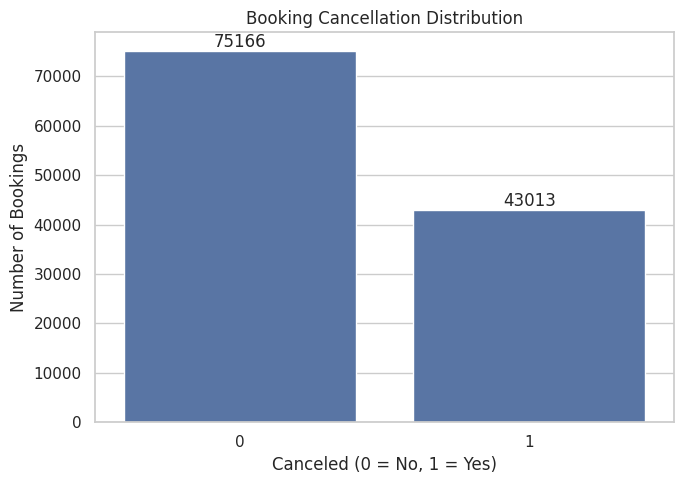

In [11]:
target_counts = y.value_counts().sort_index()
target_percentages = y.value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

display(target_summary)

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=eda_df, x=TARGET)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Booking Cancellation Distribution")
plt.xlabel("Canceled (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

### 4.2 Feature Distributions

Numerical feature distributions are examined using histograms, while categorical features are examined through their most frequent categories.

This helps identify skewed distributions, dominant categories, and potentially rare values.

### Numerical distributions

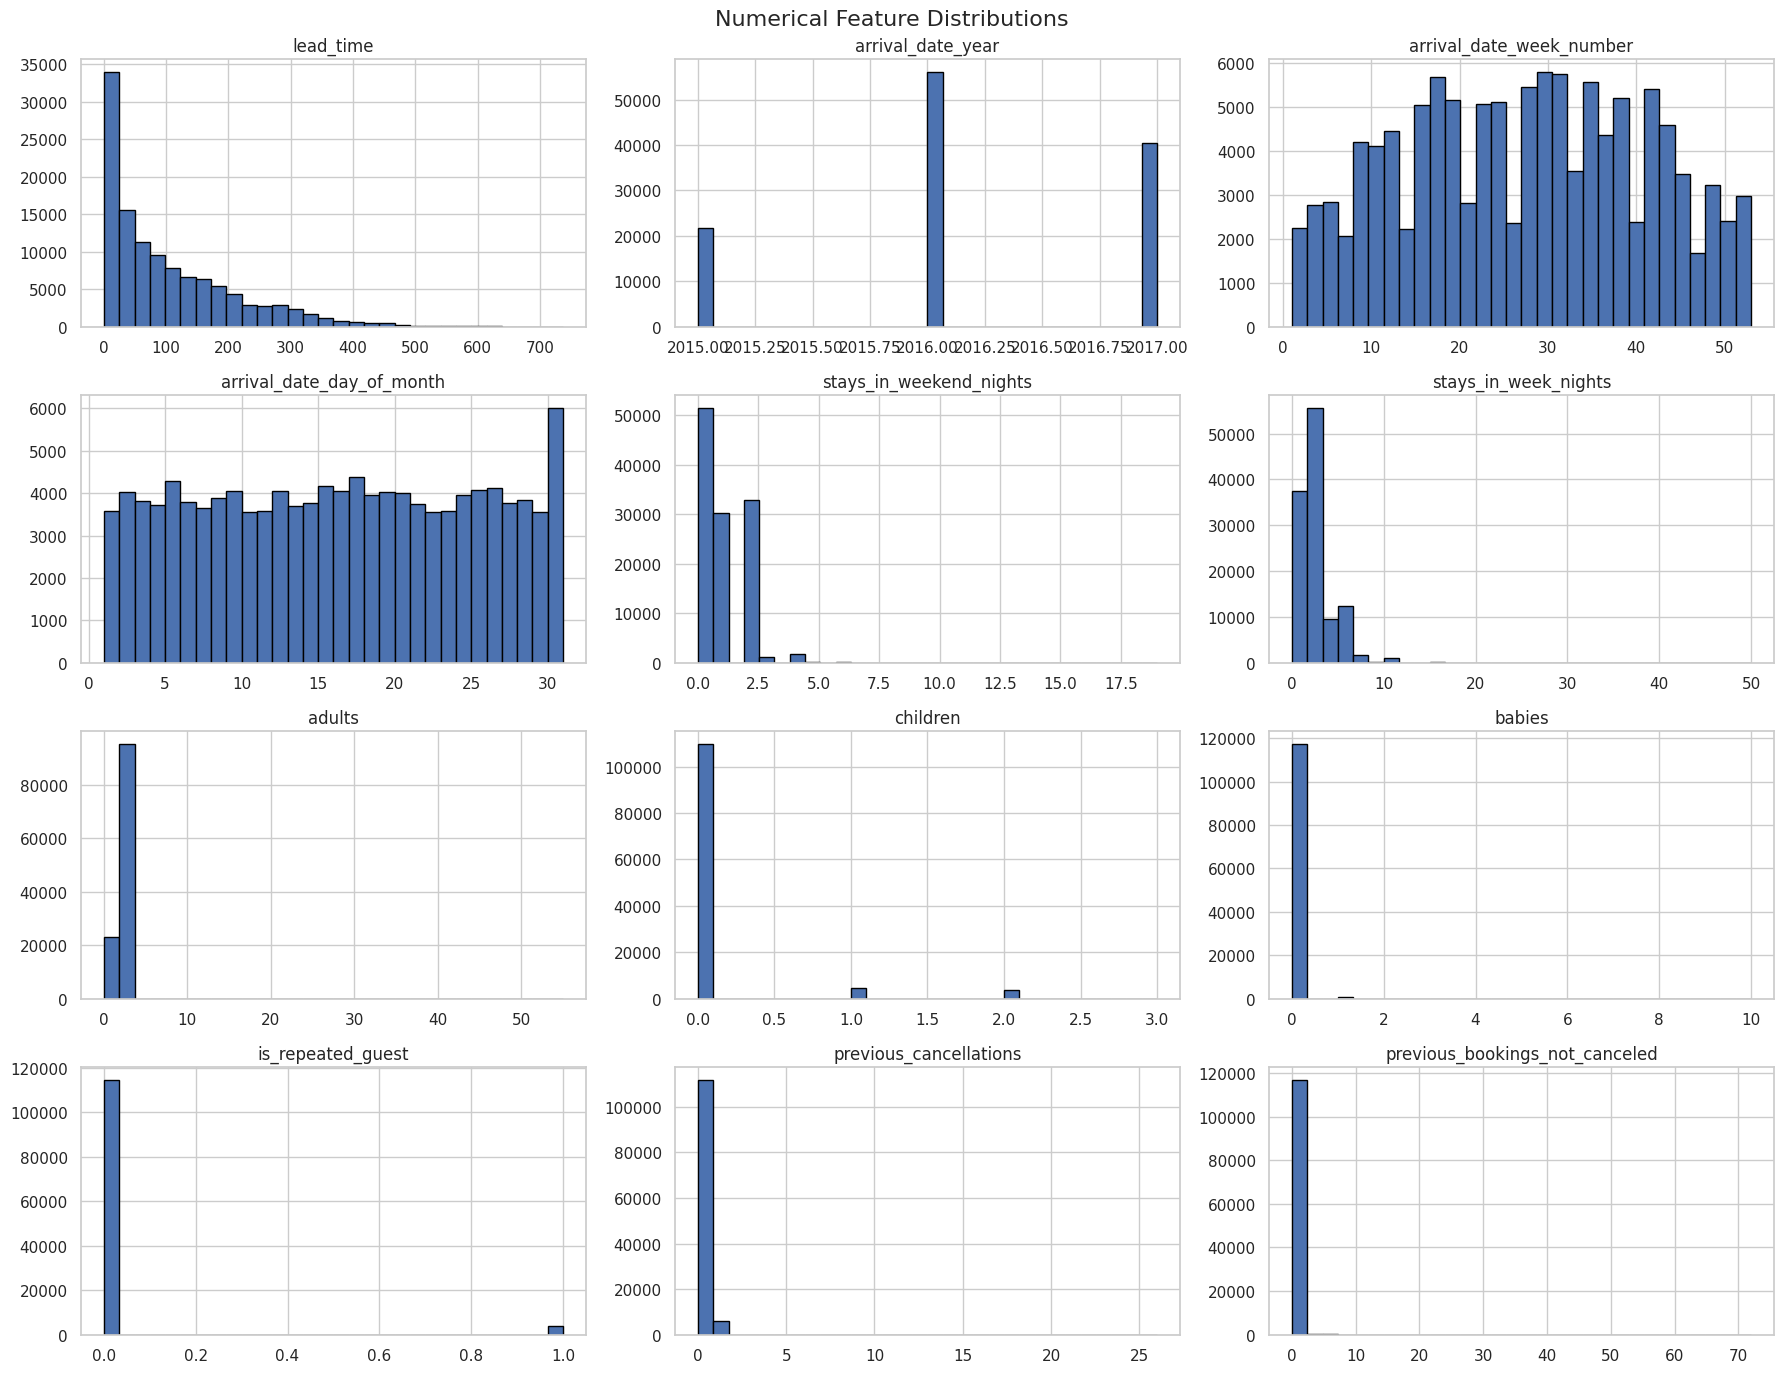

In [12]:
eda_df[numerical_features].hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

### Categorical distributions

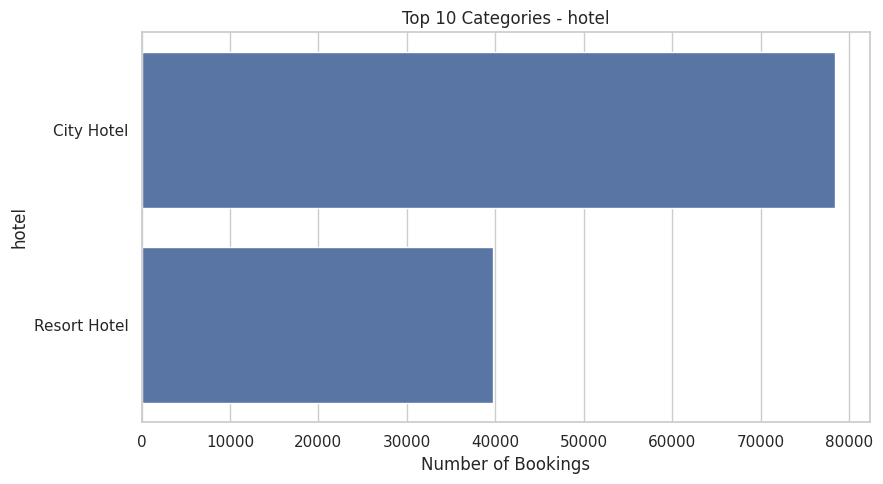


hotel - Top 10 category proportions:
hotel
City Hotel      0.663
Resort Hotel    0.337
Name: proportion, dtype: float64


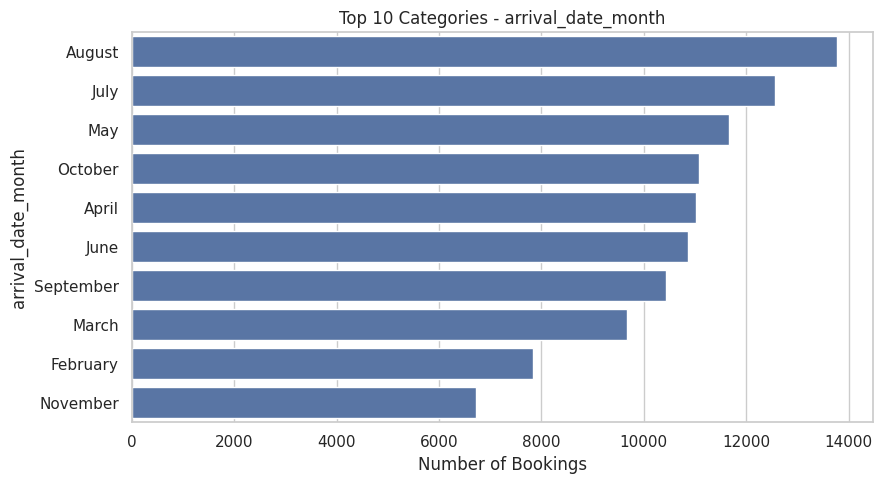


arrival_date_month - Top 10 category proportions:
arrival_date_month
August       0.117
July         0.106
May          0.099
October      0.094
April        0.093
June         0.092
September    0.088
March        0.082
February     0.066
November     0.057
Name: proportion, dtype: float64


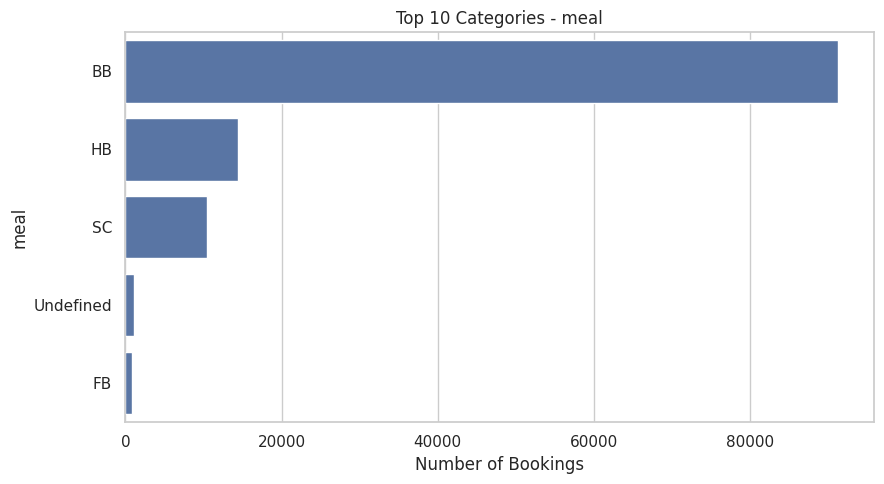


meal - Top 10 category proportions:
meal
BB           0.773
HB           0.122
SC           0.089
Undefined    0.010
FB           0.007
Name: proportion, dtype: float64


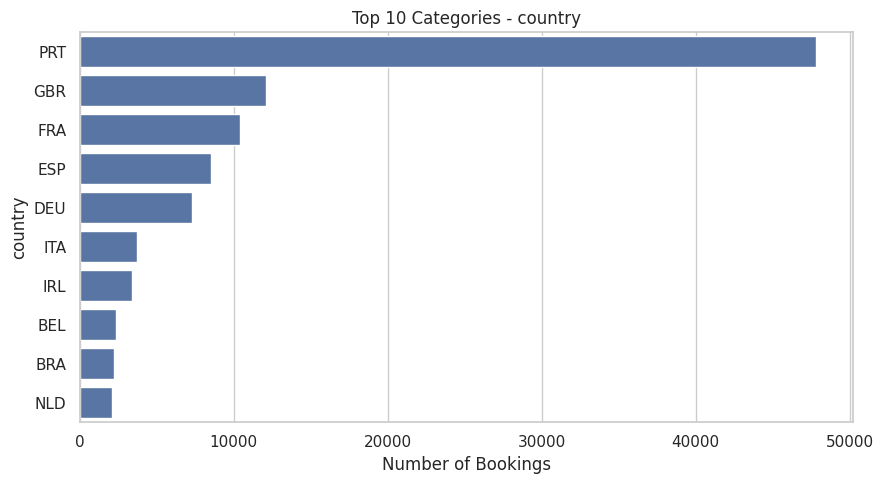


country - Top 10 category proportions:
country
PRT    0.405
GBR    0.102
FRA    0.088
ESP    0.072
DEU    0.062
ITA    0.032
IRL    0.028
BEL    0.020
BRA    0.019
NLD    0.018
Name: proportion, dtype: float64


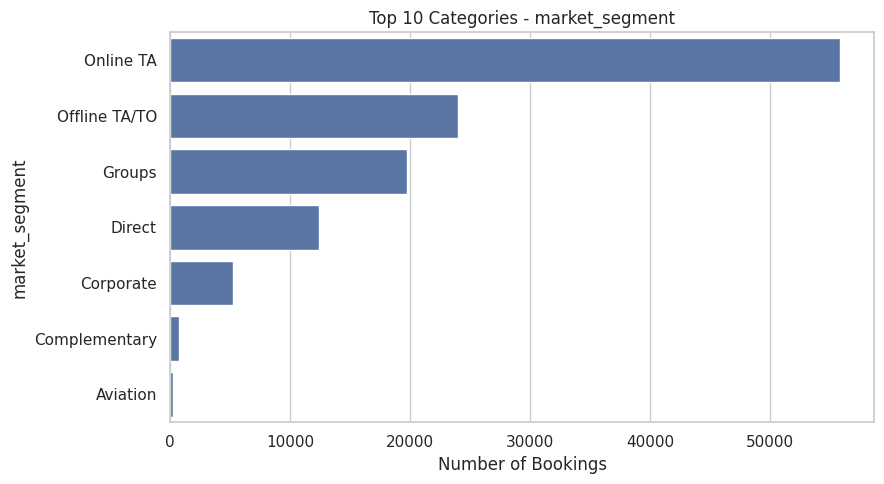


market_segment - Top 10 category proportions:
market_segment
Online TA        0.473
Offline TA/TO    0.203
Groups           0.167
Direct           0.105
Corporate        0.044
Complementary    0.006
Aviation         0.002
Name: proportion, dtype: float64


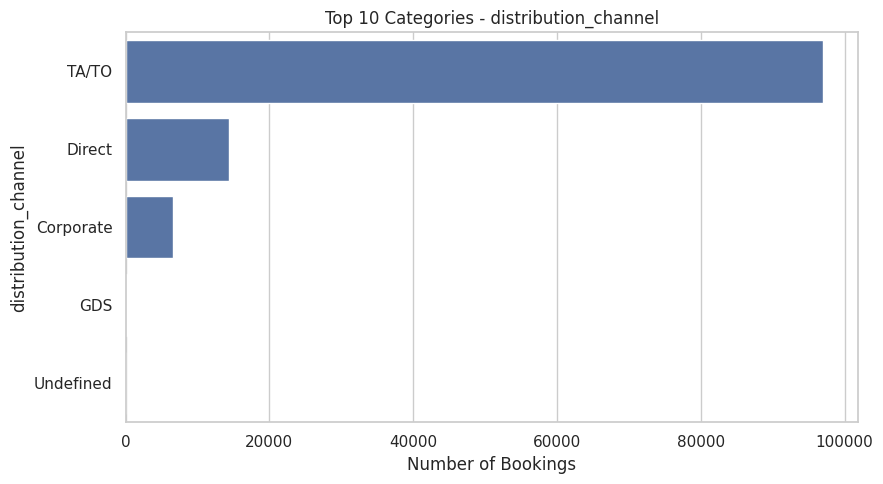


distribution_channel - Top 10 category proportions:
distribution_channel
TA/TO        0.821
Direct       0.122
Corporate    0.056
GDS          0.002
Undefined    0.000
Name: proportion, dtype: float64


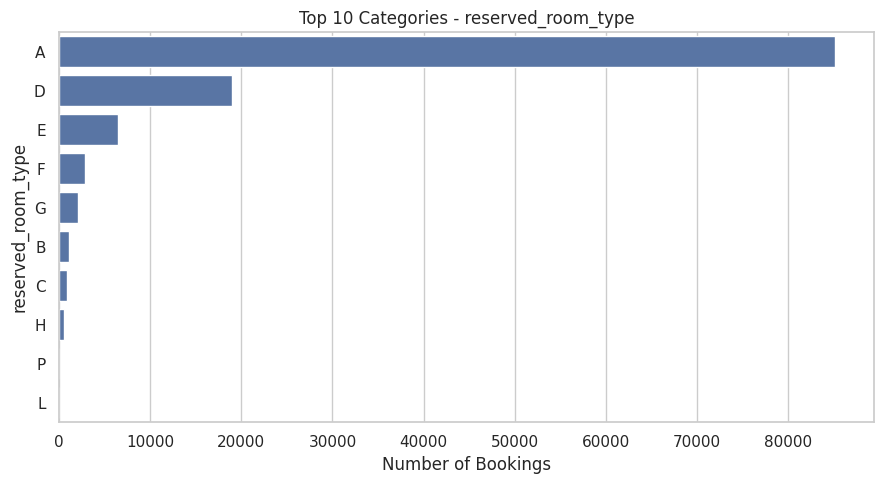


reserved_room_type - Top 10 category proportions:
reserved_room_type
A    0.720
D    0.161
E    0.055
F    0.024
G    0.018
B    0.009
C    0.008
H    0.005
P    0.000
L    0.000
Name: proportion, dtype: float64


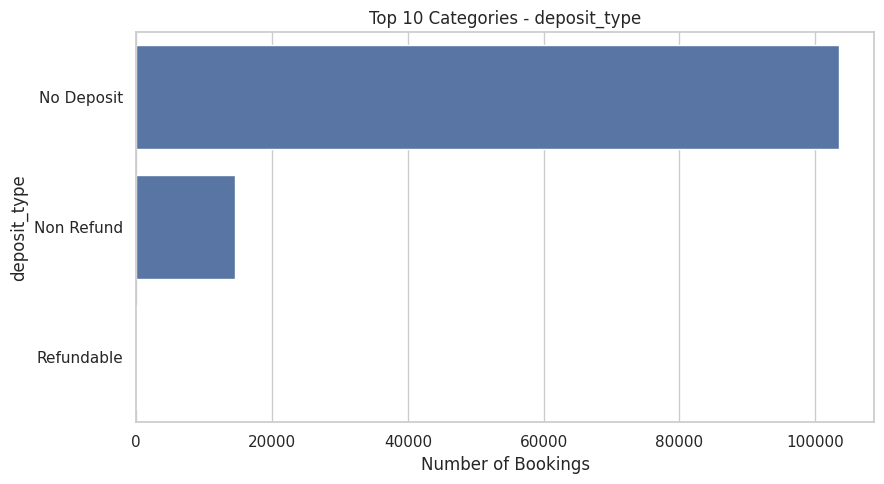


deposit_type - Top 10 category proportions:
deposit_type
No Deposit    0.875
Non Refund    0.123
Refundable    0.001
Name: proportion, dtype: float64


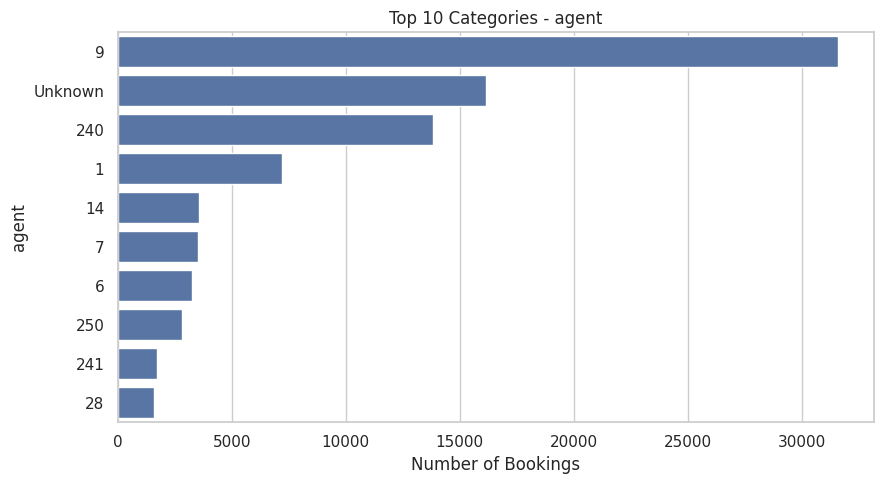


agent - Top 10 category proportions:
agent
9          0.267
Unknown    0.137
240        0.117
1          0.061
14          0.03
7           0.03
6          0.028
250        0.024
241        0.015
28         0.014
Name: proportion, dtype: Float64


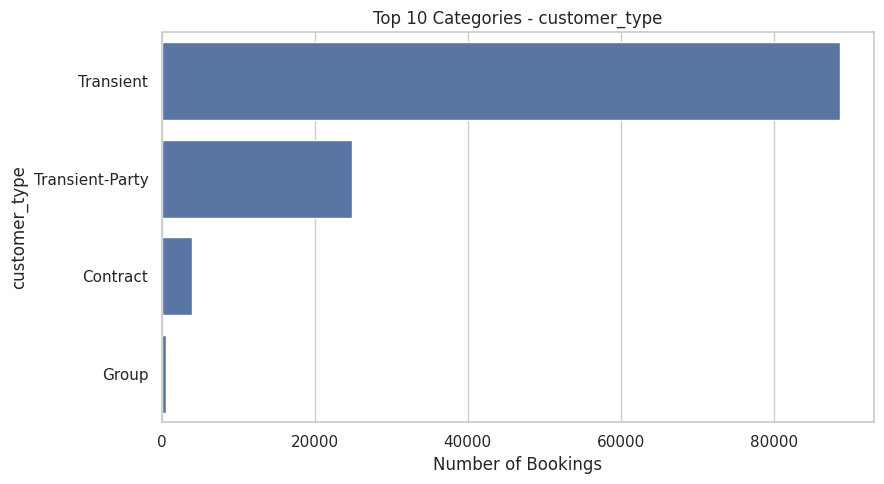


customer_type - Top 10 category proportions:
customer_type
Transient          0.750
Transient-Party    0.211
Contract           0.034
Group              0.005
Name: proportion, dtype: float64


In [13]:
for col in categorical_features:

    counts = eda_df[col].value_counts().head(10)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=counts.values,
        y=counts.index
    )

    plt.title(f"Top 10 Categories - {col}")
    plt.xlabel("Number of Bookings")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

    print(f"\n{col} - Top 10 category proportions:")
    print(
        eda_df[col]
        .value_counts(normalize=True)
        .head(10)
        .round(3)
    )

### 4.3 Feature Importance

Permutation importance is used to estimate the contribution of individual features to model performance.

A Random Forest classifier is trained as an exploratory model. Feature importance is measured on a validation set using ROC-AUC.

This analysis is exploratory and does not imply causation.

### Feature importance

In [14]:
X_train_eda, X_val_eda, y_train_eda, y_val_eda = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

eda_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

importance_model = Pipeline([
    ("preprocessor", eda_preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

importance_model.fit(X_train_eda, y_train_eda)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Calculate permutation importance

,feature,importance_mean,importance_std
19,deposit_type,0.079250,0.002496
12,country,0.076192,0.002532
21,customer_type,0.033575,0.000593
20,agent,0.029365,0.001043
1,lead_time,0.026387,0.000776
13,market_segment,0.018801,0.001024
16,previous_cancellations,0.018116,0.000880
0,hotel,0.006016,0.000179
14,distribution_channel,0.005586,0.001032
2,arrival_date_year,0.005242,0.000530


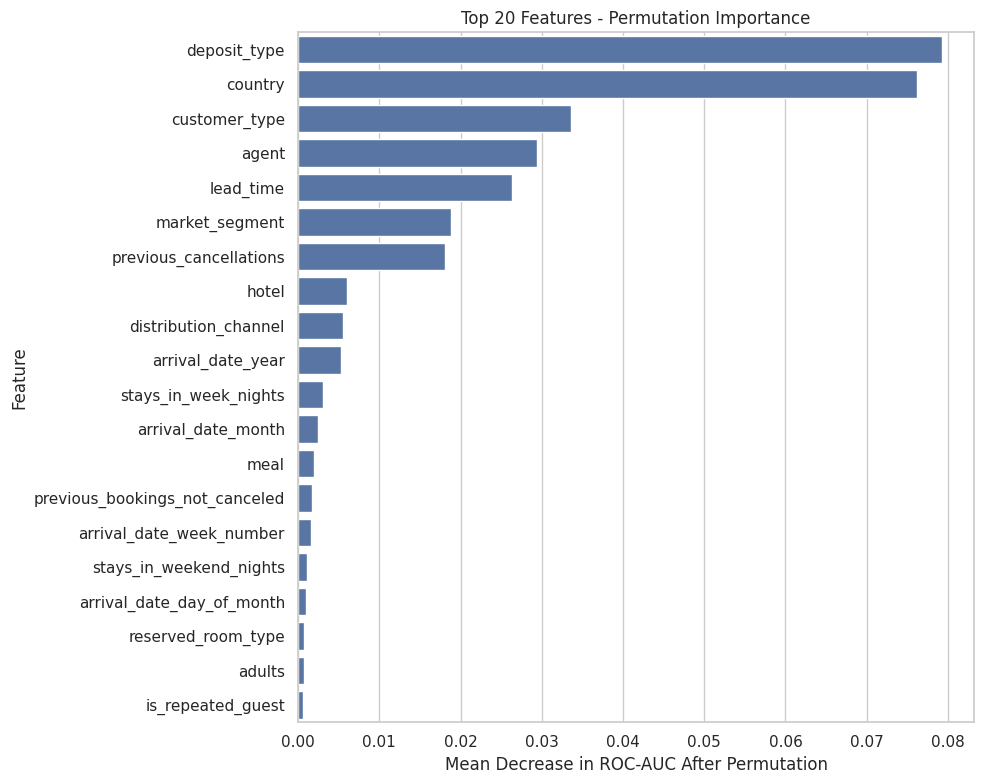

In [15]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    importance_model,
    X_val_eda,
    y_val_eda,
    n_repeats=3,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": permutation.importances_mean,
    "importance_std": permutation.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_df.head(20),
    x="importance_mean",
    y="feature"
)

plt.title("Top 20 Features - Permutation Importance")
plt.xlabel("Mean Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 4.4 Correlation with Target

Pearson correlation is calculated between numerical features and the binary target variable.

For a binary target, this is equivalent to point-biserial correlation. It measures linear association but does not capture nonlinear relationships or categorical associations.

### Correlation with target

lead_time                         0.302535
previous_cancellations            0.112417
is_repeated_guest                -0.086454
adults                            0.065349
previous_bookings_not_canceled   -0.057930
babies                           -0.032707
stays_in_week_nights              0.024442
arrival_date_year                 0.017459
arrival_date_week_number          0.011411
arrival_date_day_of_month        -0.008005
children                          0.004637
stays_in_weekend_nights          -0.004086
Name: is_canceled, dtype: float64

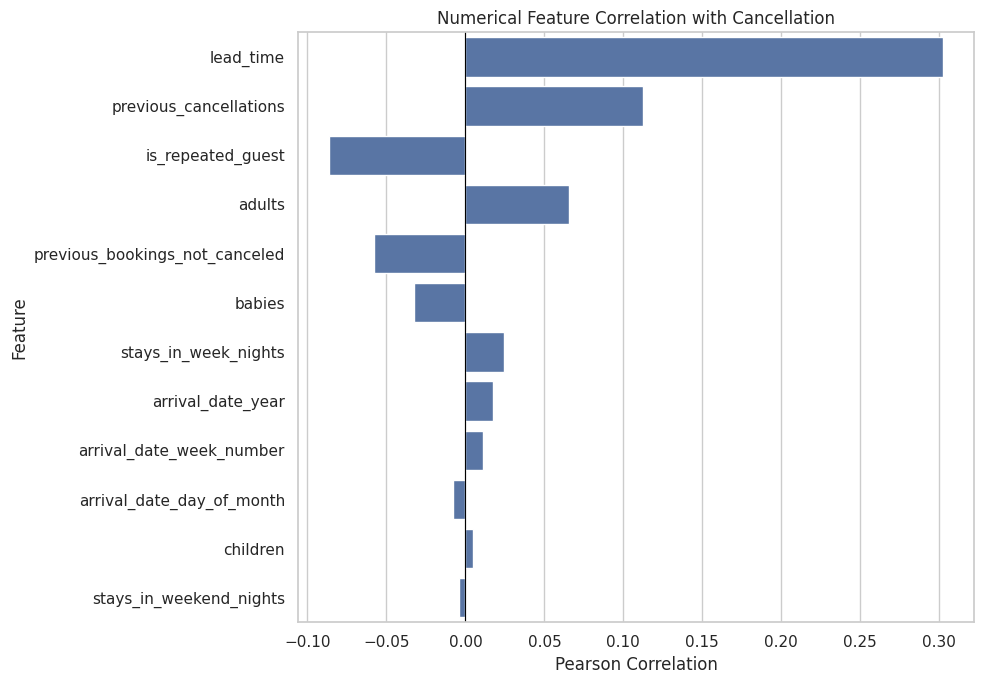

In [16]:
correlation_with_target = (
    eda_df[numerical_features + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

display(correlation_with_target)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=correlation_with_target.values,
    y=correlation_with_target.index
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Numerical Feature Correlation with Cancellation")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 4.5 Correlation Between Features

A correlation matrix is used to identify relationships and potential redundancy between numerical features.

Pairs with an absolute correlation of 0.8 or higher are highlighted for further consideration. Correlation alone is not sufficient reason to remove a feature.

### Correlation matrix

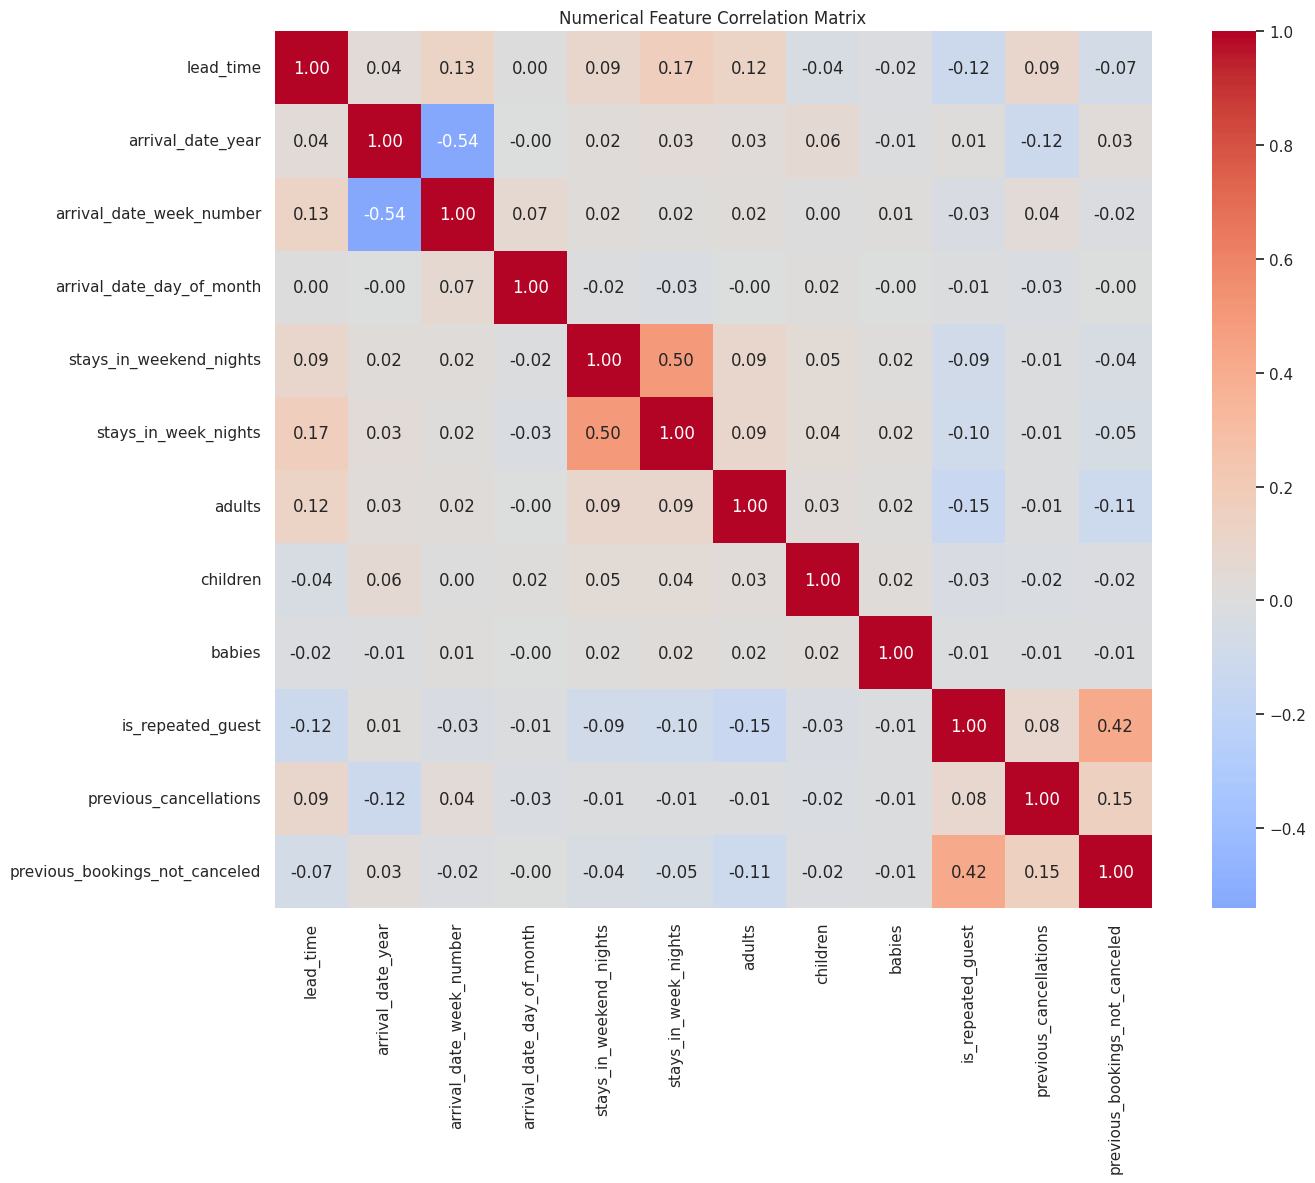

In [17]:
feature_correlation = eda_df[numerical_features].corr(
    numeric_only=True
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    feature_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Highly correlated pairs

In [18]:
upper_triangle = feature_correlation.where(
    np.triu(
        np.ones(feature_correlation.shape),
        k=1
    ).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_correlations = high_correlations[
    high_correlations["correlation"].abs() >= 0.8
].sort_values(
    "correlation",
    key=abs,
    ascending=False
)

display(high_correlations)

,feature_1,feature_2,correlation


- No feature correlation of 0.8 or higher, moving on to feature engineering.


## 5. Feature Engineering and Data Splitting

- We introduce a small number of derived features to capture additional information that may help predict booking cancellations:

- `total_nights`: Total length of stay.
- `total_guests`: Total number of guests.
- `total_previous_bookings`: Total number of previous bookings.
- `has_previous_bookings`: Whether the customer has any previous booking history.

- We retain both the original and engineered feature sets to evaluate whether feature engineering improves model performance.

- The dataset is split into training (70%), validation (15%), and test (15%) sets.

- The validation set will be used for model comparison and selection, while the test set will remain untouched until the final evaluation.


## 5.1 Group-Aware Data Splitting

- Identical feature combinations appear multiple times in the dataset. A standard random split could place these duplicates in both training and validation or test sets, potentially inflating evaluation scores.

- To prevent this, we group identical original feature combinations and ensure that all rows belonging to the same group are assigned to the same partition.

- The unique groups are randomly divided into training (70%), validation (15%), and test (15%) partitions.

- The split is not explicitly stratified. However, the cancellation rates across all three partitions are very similar to the full dataset, indicating a balanced target distribution.

- The test set remains untouched during model selection and hyperparameter tuning.

    | Split        | Cancellation rate |
    | ------------ | ----------------- |
    | Train        | 52.49%            |
    | Validation   | 52.07%            |
    | Test         | 52.11%            |
    | Full dataset | \~52.37%          |

In [19]:
TARGET = "is_canceled"

X_raw = df_imputed.drop(columns=[TARGET]).copy()
y = df_imputed[TARGET].copy()

# Feature engineering
X_engineered = X_raw.copy()

X_engineered["total_nights"] = (
    X_engineered["stays_in_weekend_nights"]
    + X_engineered["stays_in_week_nights"]
)

X_engineered["total_guests"] = (
    X_engineered["adults"]
    + X_engineered["children"]
    + X_engineered["babies"]
)

X_engineered["total_previous_bookings"] = (
    X_engineered["previous_cancellations"]
    + X_engineered["previous_bookings_not_canceled"]
)

X_engineered["has_previous_bookings"] = (
    X_engineered["total_previous_bookings"] > 0
).astype(int)

# Group identical feature rows
groups = pd.util.hash_pandas_object(X_raw, index=False)

# Split groups into train and temporary sets
group_data = pd.DataFrame({
    "group": groups,
    "target": y
}).drop_duplicates("group")

train_groups, temp_groups = train_test_split(
    group_data["group"],
    test_size=0.30,
    random_state=RANDOM_STATE
)

# Split remaining groups into validation and test
val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=RANDOM_STATE
)

train_idx = X_raw.index[groups.isin(train_groups)]
val_idx = X_raw.index[groups.isin(val_groups)]
test_idx = X_raw.index[groups.isin(test_groups)]

# Original and engineered feature sets
X_train_raw = X_raw.loc[train_idx]
X_val_raw = X_raw.loc[val_idx]
X_test_raw = X_raw.loc[test_idx]

X_train_eng = X_engineered.loc[train_idx]
X_val_eng = X_engineered.loc[val_idx]
X_test_eng = X_engineered.loc[test_idx]

# Target splits
y_train = y.loc[train_idx]
y_val = y.loc[val_idx]
y_test = y.loc[test_idx]

print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:", X_test_raw.shape)

print("\nTarget proportions:")
print("Train:", round(y_train.mean(), 4))
print("Validation:", round(y_val.mean(), 4))
print("Test:", round(y_test.mean(), 4))

print("\nFeature counts:")
print("Original:", X_train_raw.shape[1])
print("Engineered:", X_train_eng.shape[1])

Training: (83103, 22)
Validation: (17515, 22)
Test: (17561, 22)

Target proportions:
Train: 0.3682
Validation: 0.3613
Test: 0.3467

Feature counts:
Original: 22
Engineered: 26


## 6. Model Training and Evaluation

Five classification algorithms are compared using two feature sets: the original features and the engineered features.

**Models:**
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- CatBoost

**Preprocessing:**
- Categorical features are one-hot encoded for scikit-learn models and XGBoost.
- Numerical features are standardized for Logistic Regression and passed through unchanged for tree-based models.
- CatBoost uses its native categorical feature handling.

Preprocessing is configured separately for each feature set to ensure that all original and engineered features are included in the experiments.

All models are trained using the training set and evaluated using the same validation set.

**Evaluation metrics:**
- ROC-AUC
- PR-AUC (Average Precision)
- Precision
- Recall
- F1-score

The validation results are used to compare models and select a candidate for further tuning. The test set remains untouched during this stage.

In [20]:
def make_preprocessor(X, scale_numeric=False):
    categorical_features = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    numerical_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    numerical_transformer = (
        StandardScaler() if scale_numeric else "passthrough"
    )

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            (
                "numerical",
                numerical_transformer,
                numerical_features
            )
        ]
    )


def get_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=150,
            max_depth=16,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=250,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }


trained_models = {}
experiment_results = []

feature_sets = {
    "Original": (X_train_raw, X_val_raw),
    "Engineered": (X_train_eng, X_val_eng)
}

for feature_set_name, (X_train, X_val) in feature_sets.items():

    # Train scikit-learn models and XGBoost
    for model_name, model in get_models().items():

        pipeline = Pipeline([
            (
                "preprocessor",
                make_preprocessor(
                    X_train,
                    scale_numeric=(model_name == "Logistic Regression")
                )
            ),
            ("classifier", model)
        ])

        pipeline.fit(X_train, y_train)

        y_proba = pipeline.predict_proba(X_val)[:, 1]
        y_pred = (y_proba >= 0.5).astype(int)

        experiment_results.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            "ROC-AUC": roc_auc_score(y_val, y_proba),
            "PR-AUC": average_precision_score(y_val, y_proba),
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_val, y_pred, zero_division=0
            )
        })

        trained_models[(feature_set_name, model_name)] = pipeline

        print(f"Completed: {feature_set_name} - {model_name}")

    # Train CatBoost with native categorical feature handling
    cat_cols = X_train.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    X_train_cb = X_train.copy()
    X_val_cb = X_val.copy()

    for col in cat_cols:
        X_train_cb[col] = X_train_cb[col].astype(str)
        X_val_cb[col] = X_val_cb[col].astype(str)

    catboost_model = CatBoostClassifier(
        iterations=300,
        depth=7,
        learning_rate=0.1,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=-1,
        allow_writing_files=False
    )

    catboost_model.fit(
        X_train_cb,
        y_train,
        cat_features=cat_cols
    )

    y_proba = catboost_model.predict_proba(X_val_cb)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    experiment_results.append({
        "Feature Set": feature_set_name,
        "Model": "CatBoost",
        "ROC-AUC": roc_auc_score(y_val, y_proba),
        "PR-AUC": average_precision_score(y_val, y_proba),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        )
    })

    trained_models[(feature_set_name, "CatBoost")] = catboost_model

    print(f"Completed: {feature_set_name} - CatBoost")


# Compare all experiments
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Completed: Original - Logistic Regression
Completed: Original - Decision Tree
Completed: Original - Random Forest
Completed: Original - XGBoost


KeyboardInterrupt: 

### 6.1 Hyperparameter Tuning

- Logistic Regression and CatBoost were selected for hyperparameter tuning to compare a linear model with a gradient-boosted tree-based model.

- Both models are tuned using the training set and evaluated on the validation set.

- ROC-AUC is used as the primary selection metric. The test set remains untouched during tuning.

In [21]:
from sklearn.model_selection import GridSearchCV

# Preprocessing for Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(
        X_train_raw,
        scale_numeric=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_params,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

logistic_search.fit(X_train_raw, y_train)

print("Logistic Regression best parameters:")
print(logistic_search.best_params_)
print("Best CV ROC-AUC:", round(logistic_search.best_score_, 4))


# CatBoost tuning
catboost_train = X_train_raw.copy()
catboost_val = X_val_raw.copy()

cat_cols = catboost_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in cat_cols:
    catboost_train[col] = catboost_train[col].astype(str)
    catboost_val[col] = catboost_val[col].astype(str)

catboost_base = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=50,
    thread_count=-1,
    allow_writing_files=False
)

catboost_params = {
    "iterations": [300, 500],
    "depth": [5, 7, 9],
    "learning_rate": [0.05, 0.1],
    "l2_leaf_reg": [3]
}

catboost_search = GridSearchCV(
    catboost_base,
    catboost_params,
    scoring="roc_auc",
    cv=3,
    n_jobs=1,
    verbose=1
)

catboost_search.fit(
    catboost_train,
    y_train,
    cat_features=cat_cols
)

print("\nCatBoost best parameters:")
print(catboost_search.best_params_)
print("Best CV ROC-AUC:", round(catboost_search.best_score_, 4))


# Evaluate both tuned models on validation data
tuned_models = {
    "Logistic Regression": logistic_search.best_estimator_,
    "CatBoost": catboost_search.best_estimator_
}

tuning_results = []

for model_name, model in tuned_models.items():

    if model_name == "CatBoost":
        y_proba = model.predict_proba(catboost_val)[:, 1]
    else:
        y_proba = model.predict_proba(X_val_raw)[:, 1]

    y_pred = (y_proba >= 0.5).astype(int)

    tuning_results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_val, y_proba),
        "PR-AUC": average_precision_score(y_val, y_proba),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred)
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Logistic Regression best parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8372
Fitting 3 folds for each of 12 candidates, totalling 36 fits
0:	total: 35ms	remaining: 10.5s
50:	total: 1.41s	remaining: 6.89s
100:	total: 2.95s	remaining: 5.81s
150:	total: 4.79s	remaining: 4.72s


KeyboardInterrupt: 

In [22]:
print(cat_cols)
print(catboost_search.best_estimator_.get_params())
print("Best CV ROC-AUC:", catboost_search.best_score_)

['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


AttributeError: 'GridSearchCV' object has no attribute 'best_estimator_'

In [23]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Combine training and validation sets
X_train_final = pd.concat([X_train_raw, X_val_raw])
y_train_final = pd.concat([y_train, y_val])

# Prepare categorical columns
X_train_final = X_train_final.copy()
X_test_final = X_test_raw.copy()

for col in cat_cols:
    X_train_final[col] = X_train_final[col].astype(str)
    X_test_final[col] = X_test_final[col].astype(str)

# Train final model
final_model = CatBoostClassifier(
    iterations=300,
    depth=9,
    learning_rate=0.05,
    l2_leaf_reg=3,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=1,
    allow_writing_files=False
)

final_model.fit(
    X_train_final,
    y_train_final,
    cat_features=cat_cols
)

# Evaluate once on the test set
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]
y_test_pred = (y_test_proba >= 0.5).astype(int)

print("Final Test Results")
print("------------------")
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_proba), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_test_proba), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1:", round(f1_score(y_test, y_test_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

0:	total: 76ms	remaining: 22.7s
1:	total: 178ms	remaining: 26.5s
2:	total: 279ms	remaining: 27.6s
3:	total: 384ms	remaining: 28.4s
4:	total: 478ms	remaining: 28.2s
5:	total: 595ms	remaining: 29.1s
6:	total: 707ms	remaining: 29.6s
7:	total: 798ms	remaining: 29.1s
8:	total: 906ms	remaining: 29.3s
9:	total: 1.02s	remaining: 29.5s
10:	total: 1.13s	remaining: 29.8s
11:	total: 1.24s	remaining: 29.7s
12:	total: 1.34s	remaining: 29.5s
13:	total: 1.43s	remaining: 29.3s
14:	total: 1.54s	remaining: 29.3s
15:	total: 1.64s	remaining: 29.2s
16:	total: 1.76s	remaining: 29.3s
17:	total: 1.87s	remaining: 29.3s
18:	total: 1.99s	remaining: 29.4s
19:	total: 2.11s	remaining: 29.5s
20:	total: 2.21s	remaining: 29.4s
21:	total: 2.3s	remaining: 29.1s
22:	total: 2.41s	remaining: 29s
23:	total: 2.51s	remaining: 28.9s
24:	total: 2.62s	remaining: 28.8s
25:	total: 2.74s	remaining: 28.8s
26:	total: 2.84s	remaining: 28.7s
27:	total: 2.93s	remaining: 28.4s
28:	total: 3.05s	remaining: 28.5s
29:	total: 3.16s	remaining: 

In [24]:
print("Train + validation:")
print(y_train_final.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))

print("\nTest probability range:")
print(y_test_proba.min(), y_test_proba.max())

print("\nTest ROC-AUC:")
print(roc_auc_score(y_test, y_test_proba))

Train + validation:
is_canceled
0    0.633018
1    0.366982
Name: proportion, dtype: float64

Test:
is_canceled
0    0.653323
1    0.346677
Name: proportion, dtype: float64

Test probability range:
0.00019161113463199994 0.9999847594063208

Test ROC-AUC:
0.9200378598418752


## 7. Save model

In [31]:
import os

os.makedirs("../models", exist_ok=True)

final_model.save_model("../models/catboost_model.cbm")

print("Model saved successfully.")

Model saved successfully.


## 8. Save training script to `train.py`

In [28]:
%%writefile ../train.py

from pathlib import Path

import pandas as pd
from catboost import CatBoostClassifier


# --------------------------------------------------
# Configuration
# --------------------------------------------------

RANDOM_STATE = 42

BASE_DIR = Path(__file__).resolve().parent
DATA_PATH = BASE_DIR / "data" / "hotel_bookings.csv"
MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "catboost_model.cbm"


# --------------------------------------------------
# Load data
# --------------------------------------------------

def load_data():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Dataset not found: {DATA_PATH}"
        )

    df = pd.read_csv(DATA_PATH)

    print("Original dataset shape:", df.shape)

    return df


# --------------------------------------------------
# Preprocessing
# --------------------------------------------------

def preprocess_data(df):
    # Exclude no-show reservations
    df = df[df["reservation_status"] != "No-Show"].copy()

    # Remove rows with missing children values
    df = df.dropna(subset=["children"]).copy()

    # Drop excluded and unavailable-at-booking-time features
    columns_to_drop = [
        "company",
        "reservation_status",
        "reservation_status_date",
        "assigned_room_type",
        "booking_changes",
        "days_in_waiting_list",
        "required_car_parking_spaces",
        "total_of_special_requests",
        "adr"
    ]

    df = df.drop(columns=columns_to_drop)

    # Handle missing categorical values
    df["country"] = (
        df["country"]
        .fillna("Unknown")
        .astype(str)
    )

    df["agent"] = (
        pd.to_numeric(df["agent"], errors="coerce")
        .astype("Int64")
        .astype("string")
        .fillna("Unknown")
    )

    # Separate features and target
    target = "is_canceled"

    X = df.drop(columns=[target]).copy()
    y = df[target].copy()

    # Identify categorical features
    categorical_features = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    # Convert categorical features to strings
    for col in categorical_features:
        X[col] = X[col].fillna("Unknown").astype(str)

    print("Processed dataset shape:", X.shape)
    print("Number of features:", len(X.columns))
    print("Categorical features:", categorical_features)

    return X, y, categorical_features


# --------------------------------------------------
# Train model
# --------------------------------------------------

def train_model(X, y, categorical_features):
    model = CatBoostClassifier(
        iterations=300,
        depth=9,
        learning_rate=0.05,
        l2_leaf_reg=3,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X,
        y,
        cat_features=categorical_features
    )

    return model


# --------------------------------------------------
# Save model
# --------------------------------------------------

def save_model(model):
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    model.save_model(str(MODEL_PATH))

    print(f"Model saved to: {MODEL_PATH}")


# --------------------------------------------------
# Main
# --------------------------------------------------

def main():
    df = load_data()

    X, y, categorical_features = preprocess_data(df)

    model = train_model(
        X,
        y,
        categorical_features
    )

    save_model(model)

    print("Training completed successfully.")


if __name__ == "__main__":
    main()


Writing ../train.py


## 9. Create and save prediction script to `predict.py`

In [30]:

%%writefile ../predict.py

from pathlib import Path

import pandas as pd
from catboost import CatBoostClassifier
from fastapi import FastAPI
from pydantic import BaseModel


# --------------------------------------------------
# Configuration
# --------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "catboost_model.cbm"

FEATURE_COLUMNS = [
    "hotel",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "customer_type"
]

CATEGORICAL_FEATURES = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "agent",
    "customer_type"
]


# --------------------------------------------------
# Load model
# --------------------------------------------------

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}. Run train.py first."
    )

model = CatBoostClassifier()
model.load_model(str(MODEL_PATH))


# --------------------------------------------------
# FastAPI application
# --------------------------------------------------

app = FastAPI(
    title="Hotel Booking Cancellation Prediction",
    description="Predict the probability that a hotel booking will be canceled.",
    version="1.0.0"
)


# --------------------------------------------------
# Input schema
# --------------------------------------------------

class Booking(BaseModel):
    hotel: str
    lead_time: int
    arrival_date_year: int
    arrival_date_month: str
    arrival_date_week_number: int
    arrival_date_day_of_month: int
    stays_in_weekend_nights: int
    stays_in_week_nights: int
    adults: int
    children: float
    babies: int
    meal: str
    country: str
    market_segment: str
    distribution_channel: str
    is_repeated_guest: int
    previous_cancellations: int
    previous_bookings_not_canceled: int
    reserved_room_type: str
    deposit_type: str
    agent: str
    customer_type: str


# --------------------------------------------------
# Endpoints
# --------------------------------------------------

@app.get("/")
def home():
    return {
        "message": "Hotel Booking Cancellation Prediction API",
        "docs": "/docs"
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


@app.post("/predict")
def predict(booking: Booking):

    # Convert input into a DataFrame
    booking_data = pd.DataFrame([booking.dict()])

    # Preserve training feature order
    booking_data = booking_data[FEATURE_COLUMNS]

    # Ensure categorical features are strings
    for col in CATEGORICAL_FEATURES:
        booking_data[col] = booking_data[col].astype(str)

    # Generate prediction
    probability = float(
        model.predict_proba(booking_data)[0, 1]
    )

    prediction = int(probability >= 0.5)

    return {
        "cancellation_probability": round(probability, 4),
        "prediction": prediction,
        "prediction_label": (
            "Canceled" if prediction == 1 else "Not Canceled"
        )
    }


Writing ../predict.py
